# Make predict of all patchs colected from images TIF in planet

## Load all packages from python

In [1]:
import cv2
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from IPython.display import Image
import pydot
import graphviz

In [ ]:
# Tensorflow setup.
import os
import tensorflow as tf
print("We working with TF Version = ", tf.__version__)
# tf.enable_eager_execution()

device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
  raise SystemError('GPU device not found')
print('Found GPU at: {}'.format(device_name))

We working with TF Version =  2.17.1
Found GPU at: /device:GPU:0


In [4]:
from keras.models import Model
from keras.layers import Input, Conv2D, MaxPooling2D, concatenate, Conv2DTranspose
from keras.layers import BatchNormalization, Dropout, Lambda, UpSampling2D
from keras.optimizers import Adam
from keras.layers import Activation, MaxPool2D, Concatenate

In [5]:
# Cloud authentication.
from google.colab import auth
auth.authenticate_user()

In [7]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [8]:
path_patchInput = '/content/drive/MyDrive/patches_FotoVnpy/patches_FotoVv21'
# path_patchInput = '/content/drive/MyDrive/patches_FotoVnpy/patch_fails'
path_patchOutput = '/content/drive/MyDrive/patches_FotoVnpy/patches_pred_FotoVv2'
lstfilepath = glob.glob(path_patchInput + '/*.npy')
print(f"we load {len(lstfilepath)} file npy")
for ii in lstfilepath[:5]:
    print(ii)

we load 2202 file npy
/content/drive/MyDrive/patches_FotoVnpy/patches_FotoVv21/00000000000000000069g150.npy
/content/drive/MyDrive/patches_FotoVnpy/patches_FotoVv21/00000000000000000069g70.npy
/content/drive/MyDrive/patches_FotoVnpy/patches_FotoVv21/00000000000000000069g72.npy
/content/drive/MyDrive/patches_FotoVnpy/patches_FotoVv21/00000000000000000069g79.npy
/content/drive/MyDrive/patches_FotoVnpy/patches_FotoVv21/00000000000000000069g171.npy


In [9]:
pular = True
if not pular:
    lst24 = []
    naoSize = []
    for mpath in lstfilepath:
        if '00000000000000000024' in mpath:
            lst24.append(mpath)
        nArray = np.load(mpath)
        # print(nArray.shape)
        if nArray.shape == [256,256,10]:
            naoSize.append(mpath)
    print(f"we have {len(lst24)} array in 00000000000000000024")

    for cc, pp in enumerate(naoSize):
        print(f" # {cc} fail >> ", pp)

### Load models and predict singles arrays

In [10]:
VERSION = '1'
# modelUNet = get_modelUNetAttention()
dir_path_model = '/content/drive/MyDrive/energias/'
keras_MODEL_DIR = dir_path_model + 'model/model_10_12_2024.keras'
reg_csv_training = dir_path_model + 'registros/valores_accuracy_histogram_10_12.csv'
print("modelo keras save in => ", keras_MODEL_DIR)
print("historico de treino ", reg_csv_training)

modelo keras save in =>  /content/drive/MyDrive/energias/model/model_10_12_2024.keras
historico de treino  /content/drive/MyDrive/energias/registros/valores_accuracy_histogram_10_12.csv


In [11]:
dfVal = None
csv_saved = True
try:
    dfVal = pd.read_csv(reg_csv_training)
    dfVal.head(2)
except:
    csv_saved = False
    print(" csv not found !")

 csv not found !


In [12]:
if csv_saved:
    epochs_range = range(dfVal['accuracy'].shape[0])
    plt.figure(figsize=(18,7))
    plt.subplot(1,2,1)
    plt.plot(epochs_range, dfVal['accuracy'], label = 'Training accuracy')
    plt.plot(epochs_range, dfVal['val_accuracy'], label = 'Validation accuracy')
    plt.title('accuracy')
    plt.legend()
    plt.subplot(1,2,2)
    plt.plot(epochs_range, dfVal['loss'], label = 'Training Loss')
    plt.plot(epochs_range, dfVal['val_loss'], label = 'Validation Loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Value')
    plt.legend()
    plt.show()

In [13]:
# Recreate the exact same model, including its weights and the optimizer
mUNETtrained = tf.keras.models.load_model(keras_MODEL_DIR)
# Show the model architecture
mUNETtrained.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/saving/saving_lib.py:713: UserWarning: Skipping variable loading for optimizer 'adam', because it has 166 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "U-Net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 256, 256, 9)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d (Conv2D)           │ (None, 256, 256, 64)   │          5,248 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization       │ (None, 256, 256, 64)   │            256 │ conv2d[0][0]           │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation (Activation)   │ (None, 256, 256, 64)   │              0 │ batch_normalization[0… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_1 (Conv2D)         │ (None, 256, 256, 64)   │         36,928 │ activation[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_1     │ (None, 256, 256, 64)   │            256 │ conv2d_1[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_1 (Activation) │ (None, 256, 256, 64)   │              0 │ batch_normalization_1… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d             │ (None, 128, 128, 64)   │              0 │ activation_1[0][0]     │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_2 (Conv2D)         │ (None, 128, 128, 128)  │         73,856 │ max_pooling2d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_2     │ (None, 128, 128, 128)  │            512 │ conv2d_2[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_2 (Activation) │ (None, 128, 128, 128)  │              0 │ batch_normalization_2… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_3 (Conv2D)         │ (None, 128, 128, 128)  │        147,584 │ activation_2[0][0]     │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_3     │ (None, 128, 128, 128)  │            512 │ conv2d_3[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_3 (Activation) │ (None, 128, 128, 128)  │              0 │ batch_normalization_3… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_1           │ (None, 64, 64, 128)    │              0 │ activation_3[0][0]     │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_4 (Conv2D)         │ (None, 64, 64, 256)    │        295,168 │ max_pooling2d_1[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_4

 Total params: 93,152,709 (355.35 MB)

 Trainable params: 31,046,977 (118.43 MB)

 Non-trainable params: 11,776 (46.00 KB)

 Optimizer params: 62,093,956 (236.87 MB)

In [14]:
def hex_to_rgb(hex):
    return tuple(int(hex[i:i+2], 16) for i in (0, 2, 4))

def rgb_to_hex(r, g, b):
    return ('{:02X}' * 3).format(r, g, b)

def frame_image(img, frame_width):
    b = frame_width # border size in pixel
    ny, nx = img.shape[0], img.shape[1] # resolution / number of pixels in x and y
    if img.ndim == 3: # rgb or rgba array
        framed_img = np.zeros((b+ny+b, b+nx+b, img.shape[2]))
    elif img.ndim == 2: # grayscale image
        framed_img = np.zeros((b+ny+b, b+nx+b))
    framed_img[b:-b, b:-b] = img
    return framed_img

def convertInt16_to_Int8(myArray):
    nmin = np.min(myArray)
    nmax = np.max(myArray)
    # print("extreme before >> minimo ", nmin, "  |  maximo ", nmax)
    newArray = ((myArray - nmin) / (nmax - nmin)) * 255

    return newArray.astype(np.uint8)

def drawContour(segm, hexcolor):
    # Fill contour "c" with white, make all else black  #fc8d59 (251,141,89)
    colorRGB =  hex_to_rgb(hexcolor[1:])
    segm = np.array(segm)                                             #(rgb(22,33,43))
    ContourR = np.where(segm == 0, colorRGB[0], segm)
    ContourG = np.where(segm == 0, colorRGB[1], segm)
    ContourB = np.where(segm == 0, colorRGB[2], segm)

    imgSeg = np.stack([ContourR,ContourG,ContourB])
    # print(imgSeg.shape)
    imgSeg = np.transpose(imgSeg,[2, 1, 0])

    return imgSeg

In [15]:
def make_plot_predict(array_img):
    indexBands   = ['B','G','R','N','iia','evi','ri','gli', 'shape']
    bandIndex = len(indexBands)
    print("loading the first batch ")
    fig, ax = plt.subplots(figsize=[15,6], nrows=1, ncols=3)

    bnd_blue = array_img[:, : , 0]
    bnd_blue = convertInt16_to_Int8(bnd_blue.astype(np.uint16))
    bnd_green = array_img[:, : , 1]
    bnd_green = convertInt16_to_Int8(bnd_green.astype(np.uint16))
    bnd_red = array_img[:, : , 2]
    bnd_red = convertInt16_to_Int8(bnd_red.astype(np.uint16))

    imgRGB = np.stack([bnd_red, bnd_green, bnd_blue])
    imgRGB = np.transpose(imgRGB,[2, 1, 0])
    imgtest = array_img[:, : , :9] / 10000
    print("image teste ", imgtest.shape)
    imgtest = imgtest.reshape((1, 256, 256, bandIndex))

    stackedS = array_img[:, : , 9]

    predlabel = mUNETtrained.predict(imgtest, steps=1, verbose=2)
    # print("shape image predict ",predlabel.shape)
    # print("Minimo imgTest ", np.min(predlabel))
    # print("Maximo imgTest ", np.max(predlabel))
    predlabel = predlabel[0,:,:,0]
    predlabel[predlabel < 0.8] = 0
    predlabel[predlabel >= 0.8] = 1
    # predlabel = predlabel.astype(np.uint8)
    # print("Minimo imgTest ", np.min(predlabel))
    # print("Maximo imgTest ", np.max(predlabel))

    rgbLabelOri = np.array((1 - stackedS) * 255).astype(np.uint8)
    rgbLabelPred = np.array((1 - predlabel) * 255).astype(np.uint8)
    # print(rgbLabelOri)
    rgbLabelOri = drawContour(rgbLabelOri, '#3b3b3b')
    rgbLabelPred = drawContour(rgbLabelPred, '#94484c')
    rgbLabelOri = frame_image(rgbLabelOri, 2)
    rgbLabelPred = frame_image(rgbLabelPred, 2)
    #tf.contrib.summary.image(str(epoch)+" ->Input/"+str(counter), stacked[0:3], step=0)
    # print(rgbLabelOri)

    # show original image
    ax[0].set_title('Mosaico', fontsize = 12)
    ax[0].imshow(imgRGB,interpolation='nearest',vmin=0, vmax=250) # interpolation='nearest', , interpolation='none', vmin=24, vmax=250, , cv2.COLOR_BGR2RGB
    # ax[ii, 0].imshow(cv2.cvtColor(imgRGB, cv2.COLOR_BGR2RGB), interpolation='none', vmin=24, vmax=250) # interpolation='nearest',
    ax[0].xaxis.set_major_locator(ticker.NullLocator())
    ax[0].yaxis.set_major_locator(ticker.NullLocator())
    ax[1].set_title('Label Original', fontsize = 12)
    ax[1].imshow(rgbLabelOri.astype('uint8'), interpolation='none', vmin=0, vmax=255)  #interpolation='nearest',
    ax[1].xaxis.set_major_locator(ticker.NullLocator())
    ax[1].yaxis.set_major_locator(ticker.NullLocator())
    ax[2].set_title('Label Predict', fontsize = 12)
    ax[2].imshow(rgbLabelPred.astype('uint8'), interpolation='none', vmin=0, vmax=255)  # interpolation='nearest',
    ax[2].xaxis.set_major_locator(ticker.NullLocator())
    ax[2].yaxis.set_major_locator(ticker.NullLocator())

    plt.axis("off")
    plt.show()

# 721 loaded /content/drive/MyDrive/patches_FotoVnpy/patches_FotoVv21/00000000000000000043g9.npy array with shape (256, 256, 10) 
loading the first batch 
image teste  (256, 256, 9)
1/1 - 0s - 17ms/step


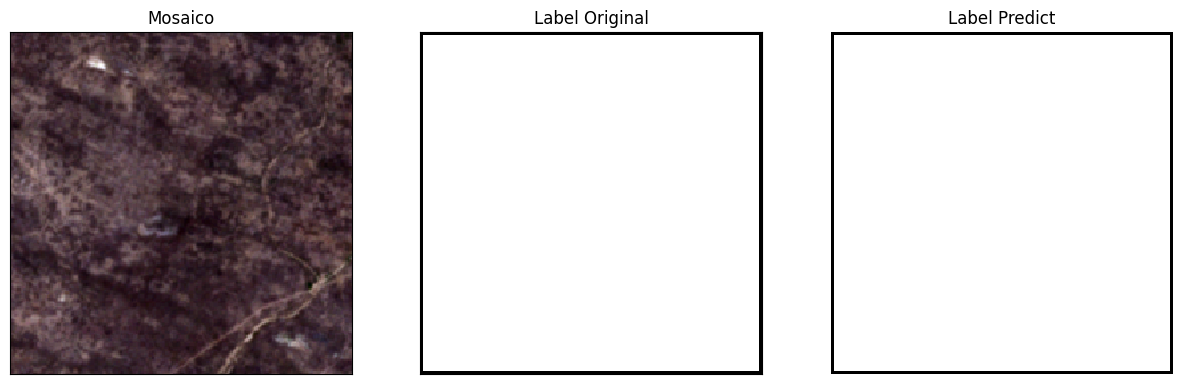

In [18]:
numArrays = len(lstfilepath)
numImgTest = random.randint(0, numArrays - 1)
# numImgTest = 43 #1434
pathImg = lstfilepath[numImgTest]
nameArray = pathImg.replace(path_patchInput + "/", "")
arrayLoaded = np.load(pathImg)
print(f"# {numImgTest} loaded {pathImg} array with shape {arrayLoaded.shape} ")
make_plot_predict(arrayLoaded)

### Process predict

In [19]:
class make_array_Predictions(object):
    path_default = ''
    pathOutput = 'array_predictV3'
    XSize = 256
    YSize = 256

    def __init__(self, model_path, path_patchsOut, path_Base):
        self.pathOutput = path_patchsOut
        self.path_Base = path_Base
        print(" patch output label predict ", self.pathOutput)
        # Recreate the exact same model, including its weights and the optimizer
        self.mUNETtrained = tf.keras.models.load_model(model_path)
        print(" ---- model loaded UNet treinado carregado ----")
        # Show the model architecture
        # self.mUNETtrained.summary()

    def save_datasetinNPY (self, arrayImg, nameMatriz):
        dirFile = os.path.join(self.pathOutput, nameMatriz)
        try:
            np.save(dirFile, np.asarray(arrayImg, dtype= np.uint8))
        except :
            print("fail Matriz Patchs ", np.asarray(arrayImg).shape)
        del arrayImg

    def load_and_predict_arrayPatchs(self, path_matrix):
        arrFails = True
        # the array is saved in the file geekfile.npy
        name_matrix = path_matrix.replace(self.path_Base, "")
        try:
            array_pred = np.load(os.path.join(path_matrix))
            print("shape matriz loaded ", array_pred.shape)
            array_pred = np.array(array_pred[:, :, :9]).reshape(1,256,256,9)
            array_pred = array_pred / 10000
            print("shape matrix ", array_pred.shape)
            predict_raster = self.mUNETtrained.predict(array_pred, steps=1, verbose=2)
            print(predict_raster.shape)
            predict_raster = predict_raster[0,:,:,0]
            print(predict_raster.shape)
            predict_raster[predict_raster < 0.8] = 0
            predict_raster[predict_raster >= 0.8] = 1
            predict_raster = predict_raster.astype(np.uint8)
            # predict_raster = predict_raster * 255
            print(f" {type(predict_raster)}  shape the image predict ", predict_raster.shape, "  maximo =  ", np.max(predict_raster) )
            self.save_datasetinNPY(predict_raster, name_matrix)

        except:
            print(" array fail ", name_matrix)
            arrFails = False

        return arrFails

In [20]:
# instanciar a classe predict
npath_base = '/content/drive/MyDrive/patches_FotoVnpy/patches_FotoVv21/'      # patches_FotoV
makepredictionclass = make_array_Predictions(keras_MODEL_DIR, path_patchOutput, npath_base)

 patch output label predict  /content/drive/MyDrive/patches_FotoVnpy/patches_pred_FotoVv2
 ---- model loaded UNet treinado carregado ----


In [21]:
nTotal = len(lstfilepath)
lstArrayFails = []
for cc, namefile in enumerate(lstfilepath[:]):
    name_array = namefile.replace(npath_base, '')
    print(f"# {cc}/{nTotal} processando = {name_array}")
    array_process =  makepredictionclass.load_and_predict_arrayPatchs(namefile)
    if not array_process :
        lstArrayFails.append(name_array)
        print(f" {name_array} >> falloooo <<< ")

    # print(array_process.shape, arrayPred.shape)
    # make_plot_toShow_predict(array_process, arrayPred)

Streaming output truncated to the last 5000 lines.
(256, 256)
 <class 'numpy.ndarray'>  shape the image predict  (256, 256)   maximo =   0
# 1488/2202 processando = 0000000000000000002cg18.npy
shape matriz loaded  (256, 256, 10)
shape matrix  (1, 256, 256, 9)
1/1 - 0s - 17ms/step
(1, 256, 256, 1)
(256, 256)
 <class 'numpy.ndarray'>  shape the image predict  (256, 256)   maximo =   0
# 1489/2202 processando = 00000000000000000077g25.npy
shape matriz loaded  (256, 256, 10)
shape matrix  (1, 256, 256, 9)
1/1 - 0s - 17ms/step
(1, 256, 256, 1)
(256, 256)
 <class 'numpy.ndarray'>  shape the image predict  (256, 256)   maximo =   0
# 1490/2202 processando = 00000000000000000077g36.npy
shape matriz loaded  (256, 256, 10)
shape matrix  (1, 256, 256, 9)
1/1 - 0s - 18ms/step
(1, 256, 256, 1)
(256, 256)
 <class 'numpy.ndarray'>  shape the image predict  (256, 256)   maximo =   1
# 1491/2202 processando = 0000000000000000005eg0.npy
shape matriz loaded  (256, 256, 10)
shape matrix  (1, 256, 256, 9)


#### se Teve problema com alguns  rodar este bloque

In [22]:
# revisar falho de um npy
print(f" we have {len(lstArrayFails)} with problems of shape")
removerFile = False
if len(lstArrayFails) > 0:
    lstArrayfail = open("lista_array_problemShape.txt", 'w')
    for nameArrf in lstArrayFails:
        array_verif = np.load(path_patchInput + '/' + nameArrf)
        print(f"name array fail << {nameArrf} >> shape of matrix  {array_verif.shape}" )
        lstArrayfail.write(nameArrf + "\n")
    removerFile = True
    lstArrayfail.close()

 we have 0 with problems of shape


In [ ]:
if removerFile:
    for cc, nameArrf in enumerate(lstArrayFails):
        # path complete
        mpathC = path_patchInput + '/' + nameArrf
        os.remove(mpathC)
        print(f" removed {nameArrf}")

In [ ]:
# force to remount drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


# Verify someone patchs saved in drive

In [ ]:
def make_plot_toShow_predict(array_img, array_label):
    indexBands   = ['B','G','R','N','iia','evi','ri','gli', 'shape']
    bandIndex = len(indexBands)
    print("loading the first batch ")
    fig, ax = plt.subplots(figsize=[15,6], nrows=1, ncols=3)

    bnd_blue = array_img[:, : , 0]
    bnd_blue = convertInt16_to_Int8(bnd_blue.astype(np.uint16))
    bnd_green = array_img[:, : , 1]
    bnd_green = convertInt16_to_Int8(bnd_green.astype(np.uint16))
    bnd_red = array_img[:, : , 2]
    bnd_red = convertInt16_to_Int8(bnd_red.astype(np.uint16))

    imgRGB = np.stack([bnd_red, bnd_green, bnd_blue])
    imgRGB = np.transpose(imgRGB,[2, 1, 0])
    imgtest = array_img[:, : , :9] / 10000
    print("image teste ", imgtest.shape)
    imgtest = imgtest.reshape((1, 256, 256, bandIndex))

    stackedS = array_img[:, : , 9]

    array_label = array_label.astype(np.uint8)
    print("Minimo imgTest ", np.min(array_label))
    print("Maximo imgTest ", np.max(array_label))


    rgbLabelOri = np.array((1 - stackedS) * 255).astype(np.uint8)
    rgbLabelPred = np.array((1 - array_label) * 255).astype(np.uint8)
    # print(rgbLabelOri)
    rgbLabelOri = drawContour(rgbLabelOri, '#3b3b3b')
    rgbLabelPred = drawContour(rgbLabelPred, '#94484c')
    rgbLabelOri = frame_image(rgbLabelOri, 2)
    rgbLabelPred = frame_image(rgbLabelPred, 2)
    #tf.contrib.summary.image(str(epoch)+" ->Input/"+str(counter), stacked[0:3], step=0)
    # print(rgbLabelOri)

    # show original image
    ax[0].set_title('Mosaico', fontsize = 12)
    ax[0].imshow(imgRGB,interpolation='nearest',vmin=0, vmax=250) # interpolation='nearest', , interpolation='none', vmin=24, vmax=250, , cv2.COLOR_BGR2RGB
    # ax[ii, 0].imshow(cv2.cvtColor(imgRGB, cv2.COLOR_BGR2RGB), interpolation='none', vmin=24, vmax=250) # interpolation='nearest',
    ax[0].xaxis.set_major_locator(ticker.NullLocator())
    ax[0].yaxis.set_major_locator(ticker.NullLocator())
    ax[1].set_title('Label Original', fontsize = 12)
    ax[1].imshow(rgbLabelOri.astype('uint8'), interpolation='none', vmin=0, vmax=255)  #interpolation='nearest',
    ax[1].xaxis.set_major_locator(ticker.NullLocator())
    ax[1].yaxis.set_major_locator(ticker.NullLocator())
    ax[2].set_title('Label Predict', fontsize = 12)
    ax[2].imshow(rgbLabelPred.astype('uint8'), interpolation='none', vmin=0, vmax=255)  # interpolation='nearest',
    ax[2].xaxis.set_major_locator(ticker.NullLocator())
    ax[2].yaxis.set_major_locator(ticker.NullLocator())

    plt.axis("off")
    plt.show()


In [ ]:
path_patchInput = '/content/drive/MyDrive/patches_FotoVnpy/patches_FotoVv21'
path_patchOutput = '/content/drive/MyDrive/patches_FotoVnpy/patches_pred_FotoV'

# 98 loaded 00000000000000000024g53.npy array with shape (256, 256, 10) 
# 98 loaded 00000000000000000024g53.npy array with shape (256, 256) 
loading the first batch 
image teste  (256, 256, 9)
Minimo imgTest  0
Maximo imgTest  1


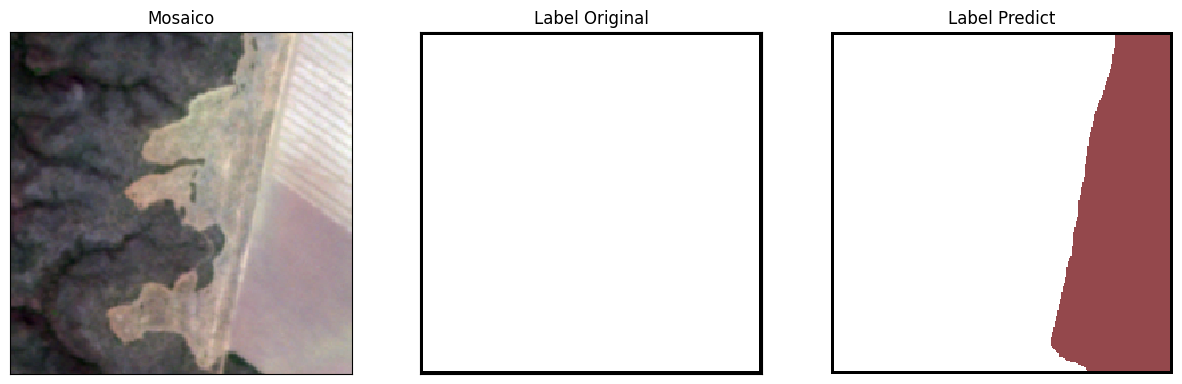

In [ ]:
numArrays = len(lstfilepath)
numImgTest = random.randint(0, numArrays - 1)
# numImgTest = 1434
pathImg = lstfilepath[numImgTest]

nameArray = pathImg.replace(path_patchInput + '/', "")
arrayLoaded = np.load(pathImg)
print(f"# {numImgTest} loaded {nameArray} array with shape {arrayLoaded.shape} ")
pathPred = path_patchOutput + '/' + nameArray
arraypredict= np.load(pathPred)
print(f"# {numImgTest} loaded {nameArray} array with shape {arraypredict.shape} ")
make_plot_toShow_predict(arrayLoaded, arraypredict)

#### move all file to folder correct

In [ ]:
import shutil

In [ ]:
path_patchInputOt1 = '/content/drive/MyDrive/patches_FotoVnpy/patch_fails'
path_patchInputOt2 = '/content/drive/MyDrive/patches_FotoVnpy/patches_FotoV2'
path_patchInput = '/content/drive/MyDrive/patches_FotoVnpy/patches_FotoV'

In [ ]:
pathlist = list(glob.glob(path_patchInputOt1 + '/*.npy'))
print(f" we loaded {len(pathlist)} files array npy")
print("     ", pathlist[0])

 we loaded 280 files array npy
      /content/drive/MyDrive/patches_FotoVnpy/patch_fails/00000000000000000016g16.npy


In [ ]:
for cc, mPathArr in enumerate(pathlist):
    nameArray = mPathArr.replace(path_patchInputOt1 + "/", "")
    dst = os.path.join(path_patchInput, nameArray)
    shutil.move(mPathArr, dst)

In [ ]:
# testar se todos os arquivos foram movidos
pathlist = list(glob.glob(path_patchInputOt1 + '/*.npy'))
print(f" we loaded {len(pathlist)} files array npy")

 we loaded 0 files array npy


In [ ]:
# loaded the other folder  to clean
pathlist = list(glob.glob(path_patchInputOt2 + '/*.npy'))
print(f" we loaded {len(pathlist)} files array npy")
print("     ", pathlist[0])

 we loaded 56 files array npy
      /content/drive/MyDrive/patches_FotoVnpy/patches_FotoV2/00000000000000000080g0.npy


In [ ]:
for cc, mPathArr in enumerate(pathlist):
    nameArray = mPathArr.replace(path_patchInputOt2 + "/", "")
    dst = os.path.join(path_patchInput, nameArray)
    shutil.move(mPathArr, dst)

In [ ]:
# testar se todos os arquivos foram movidos
pathlist = list(glob.glob(path_patchInputOt2 + '/*.npy'))
print(f" we loaded {len(pathlist)} files array npy")

 we loaded 0 files array npy
